<a href="https://colab.research.google.com/github/DWill80z/D.Will/blob/main/Broward's_Wealth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pygris


In [2]:
import os
os.environ["CENSUS_API_KEY"] = "c4734560ae1b1faf341302a811319237134aff04"

In [20]:
from google.colab import files
files.upload()
!mkdir -p lab01_demographics && mv lab01_broward_acs*.py lab01_demographics/lab01_broward_acs.py

Saving lab01_broward_wealth.ipynb to lab01_broward_wealth.ipynb
mv: cannot stat 'lab01_broward_acs*.py': No such file or directory


In [21]:
!python lab01_demographics/lab01_broward_acs.py

Saved 416 populated tracts to /content/data/processed/broward_tracts_acs2024.gpkg
Population: 1,977,129
Tracts with unreliable income estimates (CV > 30%): 28

Tract-level indicators (median across tracts):
med_income          76667.0
med_home_value     402450.0
med_rent             1934.0
pct_200k_plus           8.4
rent_to_income         31.2
value_to_income         5.0
pct_rent_burden        64.4
pct_no_car              4.9
pct_poc                71.4


In [5]:
import geopandas as gpd
g = gpd.read_file("data/processed/broward_tracts_acs2024.gpkg")

print("Median, all tracts:      ", g["med_income"].median())
print("Median, reliable tracts: ", g[g["income_cv"] <= 30]["med_income"].median())

g[g["income_cv"] > 30][["NAME", "med_income", "income_cv", "pop_total"]].sort_values("income_cv", ascending=False)


Median, all tracts:       76667.0
Median, reliable tracts:  78605.5


,NAME,med_income,income_cv,pop_total
4,Census Tract 920; Broward County; Florida,103750.0,48.7,3732.0
106,Census Tract 801.05; Broward County; Florida,66528.0,44.3,3922.0
49,Census Tract 1001.04; Broward County; Florida,49545.0,43.3,2718.0
151,Census Tract 916.02; Broward County; Florida,54250.0,42.6,3334.0
308,Census Tract 406.01; Broward County; Florida,117179.0,36.9,3605.0
354,Census Tract 604.05; Broward County; Florida,35938.0,36.7,2946.0
359,Census Tract 601.29; Broward County; Florida,67305.0,36.3,2344.0
382,Census Tract 1103.62; Broward County; Florida,54758.0,36.1,7156.0
80,Census Tract 701.03; Broward County; Florida,74301.0,35.2,5283.0
408,Census Tract 424; Broward County; Florida,159732.0,34.7,1387.0


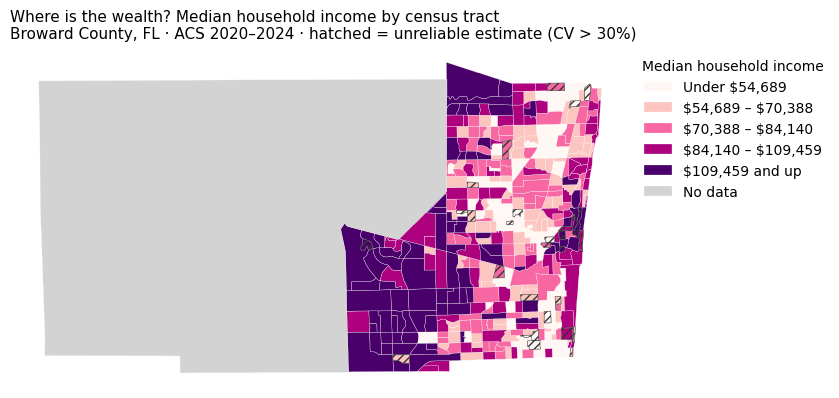

In [22]:
!pip install -q mapclassify
import geopandas as gpd, matplotlib.pyplot as plt, numpy as np

g = gpd.read_file("data/processed/broward_tracts_acs2024.gpkg")
shaky = g[g["income_cv"] > 30]

fig, ax = plt.subplots(figsize=(8, 9))
g.plot(column="med_income", scheme="quantiles", k=5, cmap="RdPu",
       edgecolor="white", linewidth=0.2, ax=ax, legend=True,
       legend_kwds={"title": "Median household income", "loc": "upper left",
                    "bbox_to_anchor": (1, 1), "frameon": False},
       missing_kwds={"color": "lightgrey", "label": "No data"})
shaky.plot(ax=ax, facecolor="none", edgecolor="#333333", hatch="////", linewidth=0.4)

# Rewrite the legend labels with $ and commas
labels = [t for t in ax.get_legend().get_texts() if "," in t.get_text()]
for i, t in enumerate(labels):
    lo, hi = (float(p) for p in t.get_text().replace(" ", "").split(","))
    if i == 0:
        t.set_text(f"Under ${hi:,.0f}")
    elif i == len(labels) - 1:
        t.set_text(f"${lo:,.0f} and up")
    else:
        t.set_text(f"${lo:,.0f} – ${hi:,.0f}")
    t.set_parse_math(False)

ax.set_title("Where is the wealth? Median household income by census tract\n"
             "Broward County, FL · ACS 2020–2024 · hatched = unreliable estimate (CV > 30%)",
             loc="left", fontsize=11)
ax.set_axis_off()
plt.savefig("map1_median_income.png", dpi=200, bbox_inches="tight")
plt.show()

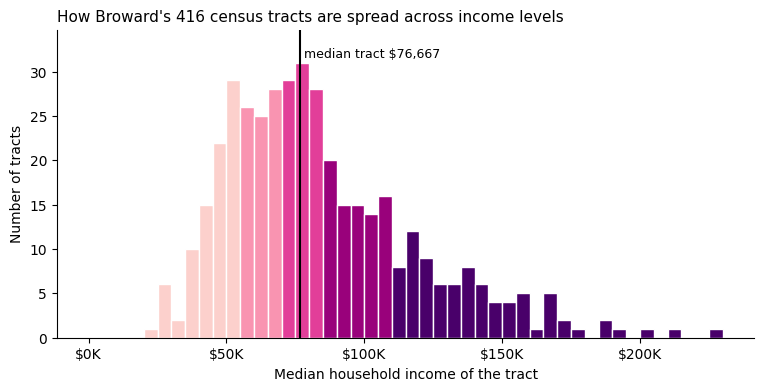

In [23]:
import mapclassify

inc = g["med_income"].dropna()
q = mapclassify.Quantiles(inc, k=5)                  # the same 5 classes as the map
colors = plt.get_cmap("RdPu")(np.linspace(0.2, 1, 5))
edges = np.arange(0, inc.max() + 5000, 5000)          # each bar covers $5K

fig, ax = plt.subplots(figsize=(9, 4))
counts, bins, bars = ax.hist(inc, bins=edges, edgecolor="white", linewidth=1)
for bar, left in zip(bars, bins[:-1]):                # color each bar by its map class
       bar.set_facecolor(colors[min(np.searchsorted(q.bins, left + 2500), 4)])

med = inc.median()
ax.axvline(med, color="black", linewidth=1.5)
ax.text(med, counts.max() * 1.02, f" median tract ${med:,.0f}", fontsize=9, parse_math=False)

ax.xaxis.set_major_formatter(lambda x, _: f"${x/1000:.0f}K")
ax.set_xlabel("Median household income of the tract")
ax.set_ylabel("Number of tracts")
ax.set_ylim(0, counts.max() * 1.12)
ax.set_title("How Broward's 416 census tracts are spread across income levels",
             loc="left", fontsize=11)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.savefig("chart_income_distribution.png", dpi=200, bbox_inches="tight")
plt.show()


In [24]:
# Add city names: find which Census city boundary each tract falls inside
from pygris import places

# Florida cities and towns (Census "places"), in the same projection as the tracts
cities = places(state="FL", year=2024, cb=True).to_crs(g.crs)[["NAME", "geometry"]]
cities = cities.rename(columns={"NAME": "city"})

# Find which city each tract's center point falls inside
pts = g.copy()
pts["geometry"] = g.representative_point()
pts = gpd.sjoin(pts, cities, how="left", predicate="within")
g["city"] = pts["city"].fillna("Unincorporated").values

# Top 10 and bottom 10 tracts by income, with city names
cols = ["city", "NAME", "med_income", "income_cv"]
top = g.sort_values("med_income", ascending=False)[cols].head(10)
bottom = g.sort_values("med_income")[cols].head(10)
print("HIGHEST-INCOME TRACTS"); display(top)
print("LOWEST-INCOME TRACTS");  display(bottom)


Using FIPS code '12' for input 'FL'
HIGHEST-INCOME TRACTS


,city,NAME,med_income,income_cv
339,Parkland,Census Tract 105.03; Broward County; Florida,225795.0,8.0
117,Weston,Census Tract 703.30; Broward County; Florida,213894.0,6.1
206,Miramar,Census Tract 1103.60; Broward County; Florida,200670.0,14.7
10,Weston,Census Tract 703.18; Broward County; Florida,194167.0,8.0
411,Weston,Census Tract 703.19; Broward County; Florida,188355.0,5.0
303,Weston,Census Tract 703.26; Broward County; Florida,185625.0,24.7
371,Fort Lauderdale,Census Tract 420; Broward County; Florida,179896.0,22.7
243,Cooper City,Census Tract 704.02; Broward County; Florida,174375.0,9.5
129,Parkland,Census Tract 106.05; Broward County; Florida,172363.0,6.5
319,Southwest Ranches,Census Tract 703.14; Broward County; Florida,169219.0,8.9


LOWEST-INCOME TRACTS


,city,NAME,med_income,income_cv
204,Pembroke Pines,Census Tract 1103.54; Broward County; Florida,24065.0,29.7
116,Sunrise,Census Tract 602.15; Broward County; Florida,25166.0,33.3
173,Fort Lauderdale,Census Tract 415; Broward County; Florida,25389.0,7.6
355,Sunrise,Census Tract 602.14; Broward County; Florida,26717.0,12.8
1,Pompano Beach,Census Tract 304.02; Broward County; Florida,26781.0,13.9
307,Deerfield Beach,Census Tract 104.03; Broward County; Florida,28262.0,10.9
265,Pembroke Pines,Census Tract 1103.34; Broward County; Florida,29873.0,12.4
288,Pembroke Pines,Census Tract 1103.55; Broward County; Florida,30551.0,21.3
209,Hollywood,Census Tract 903.03; Broward County; Florida,31846.0,22.1
289,Lauderdale Lakes,Census Tract 503.13; Broward County; Florida,35227.0,32.4


In [33]:
# Add neighborhood names: match each tract to the nearest OpenStreetMap neighborhood within 1 mile
!pip install -q osmnx
import osmnx as ox
# 1. Download named neighborhoods in Broward from OpenStreetMap
nb = ox.features_from_place("Broward County, Florida, USA",
                            tags={"place": ["neighbourhood", "suburb", "quarter"]})
nb = nb[nb["name"].notna()][["name", "geometry"]].to_crs(g.crs)
nb["geometry"] = nb.representative_point()          # turn any shapes into single points

# 2. Match each tract to the nearest neighborhood point within 1 mile
pts = g[["geometry"]].copy()
pts["geometry"] = g.representative_point()
near = gpd.sjoin_nearest(pts, nb, how="left", max_distance=5280, distance_col="dist_ft")
near = near[~near.index.duplicated()]               # keep one match per tract
g["neighborhood"] = near["name"].reindex(g.index)

print(f"Tracts with a neighborhood name: {g['neighborhood'].notna().sum()} of {len(g)}")
g[["city", "neighborhood", "med_income"]].sort_values("med_income", ascending=False).head(10)

Tracts with a neighborhood name: 124 of 416


,city,neighborhood,med_income
339,Parkland,Parkland,225795.0
117,Weston,Windmill Reserve at Weston,213894.0
206,Miramar,NaN,200670.0
10,Weston,Weston Hills,194167.0
411,Weston,The Gables at Weston,188355.0
303,Weston,Windmill Ranch Estates at Weston,185625.0
371,Fort Lauderdale,Victoria Park,179896.0
243,Cooper City,NaN,174375.0
129,Parkland,NaN,172363.0
319,Southwest Ranches,NaN,169219.0


In [26]:
g.isna().sum()

,0
GEOID,0
NAME,0
pop_total,0
med_income,1
med_income_moe,1
income_cv,1
income_reliable,0
pct_rent_burden,3
pct_no_car,1
pct_65_plus,0


In [31]:
# Label each tract by neighborhood (OSM), or by city if no neighborhood was found
g["place_label"] = g["neighborhood"].fillna(g["city"])
g["label_source"] = g["neighborhood"].notna().map({True: "OSM neighborhood", False: "City"})

print(g["label_source"].value_counts())
g[["place_label", "label_source", "med_income"]].sort_values("med_income", ascending=False).head(10)


label_source
City                292
OSM neighborhood    124
Name: count, dtype: int64


,place_label,label_source,med_income
339,Parkland,OSM neighborhood,225795.0
117,Windmill Reserve at Weston,OSM neighborhood,213894.0
206,Miramar,City,200670.0
10,Weston Hills,OSM neighborhood,194167.0
411,The Gables at Weston,OSM neighborhood,188355.0
303,Windmill Ranch Estates at Weston,OSM neighborhood,185625.0
371,Victoria Park,OSM neighborhood,179896.0
243,Cooper City,City,174375.0
129,Parkland,City,172363.0
319,Southwest Ranches,City,169219.0


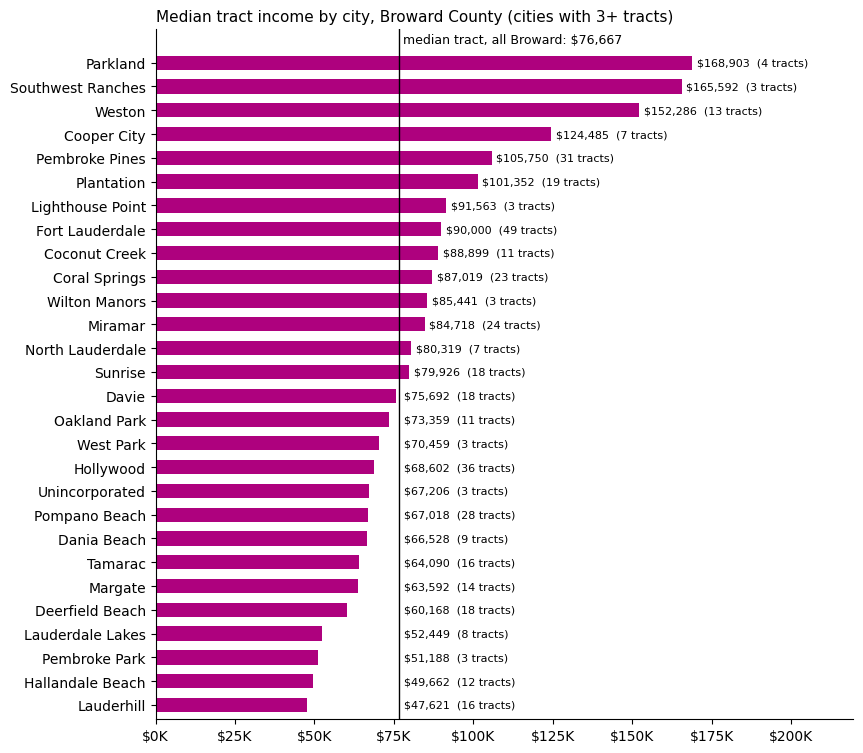

In [28]:
by_city = (g.groupby("city")
             .agg(tracts=("med_income", "size"), median_income=("med_income", "median"))
             .query("tracts >= 3")                     # skip cities with too few tracts to judge
             .sort_values("median_income"))
county_med = g["med_income"].median()

fig, ax = plt.subplots(figsize=(9, max(4, len(by_city) * 0.32)))
ax.barh(by_city.index, by_city["median_income"], color="#ae017e", height=0.6)
ax.axvline(county_med, color="black", linewidth=1)
ax.text(county_med, len(by_city) - 0.3, f" median tract, all Broward: ${county_med:,.0f}",
        fontsize=9, va="bottom", parse_math=False)
for i, (v, n) in enumerate(zip(by_city["median_income"], by_city["tracts"])):
    ax.text(max(v, county_med) + 1500, i, f"${v:,.0f}  ({n} tracts)", va="center", fontsize=8, parse_math=False)
ax.xaxis.set_major_formatter(lambda x, _: f"${x/1000:.0f}K")
ax.set_xlim(0, by_city["median_income"].max() * 1.3)
ax.set_ylim(-0.6, len(by_city) + 0.4)
ax.set_title("Median tract income by city, Broward County (cities with 3+ tracts)", loc="left", fontsize=11)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.savefig("chart_income_by_city.png", dpi=200, bbox_inches="tight")
plt.show()

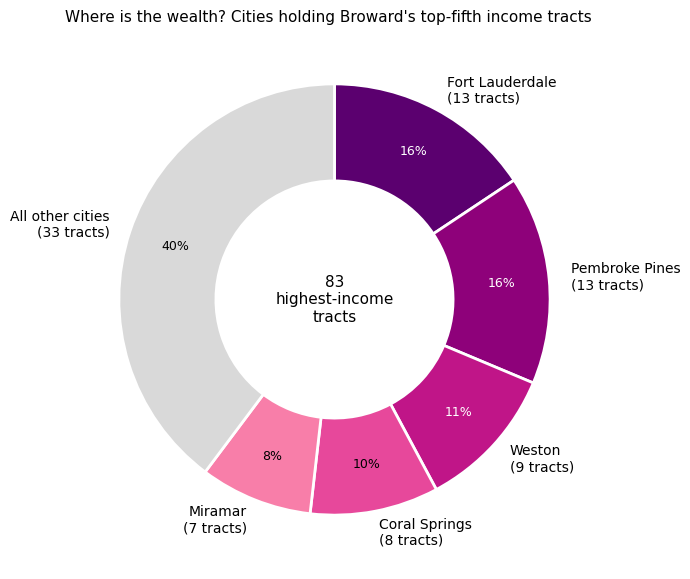

In [29]:
top = g[g["med_income"] >= g["med_income"].quantile(0.8)]          # the top fifth: the darkest class on your map
counts = top["city"].value_counts()
keep = counts.head(5)
if len(counts) > 5:
    keep["All other cities"] = counts.iloc[5:].sum()

colors = list(plt.get_cmap("RdPu")(np.linspace(0.95, 0.45, 5))) + ["#d9d9d9"]
fig, ax = plt.subplots(figsize=(7, 7))
wedges, _, pct = ax.pie(keep, labels=[f"{c}\n({n} tracts)" for c, n in keep.items()],
                        colors=colors[:len(keep)], startangle=90, counterclock=False,
                        autopct="%1.0f%%", pctdistance=0.78,
                        wedgeprops={"width": 0.45, "edgecolor": "white", "linewidth": 2})
for t, w in zip(pct, wedges):
    t.set_fontsize(9)
    t.set_color("black" if w.get_facecolor()[0] > 0.8 else "white")  # dark text on the light slices
ax.text(0, 0, f"{len(top)}\nhighest-income\ntracts", ha="center", va="center", fontsize=11)
ax.set_title("Where is the wealth? Cities holding Broward's top-fifth income tracts", loc="left", fontsize=11)
plt.savefig("chart_wealth_by_city.png", dpi=200, bbox_inches="tight")
plt.show()

In [30]:
# Compare Broward with the US
import pandas as pd

b = pd.Series({"income": 77633, "home": 414600, "rent": 1907})   # Broward
u = pd.Series({"income": 80734, "home": 332700, "rent": 1413})   # United States
money = lambda s: list(s.map("${:,.0f}".format))

table = pd.DataFrame({
    "Broward County": money(b) + [f"{b.rent*12/b.income:.1%}", f"{b.home/b.income:.1f}"],
    "United States":  money(u) + [f"{u.rent*12/u.income:.1%}", f"{u.home/u.income:.1f}"],
    "Difference":     list((b/u - 1).map("{:+.0%}".format)) + ["affordability line is 30%", "rule of thumb is about 3"],
}, index=["Median household income", "Median home value", "Median monthly gross rent",
          "A year of rent as a % of income", "Home value in years of income"])
table.index.name = "Measure (ACS 2020–2024)"

display(table)
table.to_csv("broward_vs_us.csv")

,Broward County,United States,Difference
Measure (ACS 2020–2024),,,
Median household income,"$77,633","$80,734",-4%
Median home value,"$414,600","$332,700",+25%
Median monthly gross rent,"$1,907","$1,413",+35%
A year of rent as a % of income,29.5%,21.0%,affordability line is 30%
Home value in years of income,5.3,4.1,rule of thumb is about 3
